<a href="https://colab.research.google.com/github/joseph-2412/fisica-computacional-2026-02/blob/main/Taller_4(n%C3%BAmeros_aleatorios).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Parte A — Funciones de la simulación

In [2]:
# ==============================================================================
#  A1: generar_paso(rng, a)
# ==============================================================================
def generar_paso(rng, a):
    """Un paso de longitud a: derecha si u<0.5, izquierda si u>=0.5."""
    u = rng.random()
    return a if u < 0.5 else -a


# ==============================================================================
# A2: caminar(N, a, rng)
# ==============================================================================
def caminar(N, a, rng):
    """Construye [x_0, x_1, ..., x_N] a partir del generador recibido."""
    # Validación de parámetros
    if N < 0:
        raise ValueError("El número de pasos N debe ser mayor o igual a cero.")
    if a <= 0:
        raise ValueError("La longitud del paso 'a' debe ser mayor que cero.")

    x = 0.0
    posiciones = [x]
    for _ in range(N):
        x += generar_paso(rng, a)
        posiciones.append(x)
    return posiciones

# ==============================================================================
# A3 Y A4: simular_caminatas(K, N, a, semilla, generador=None)
# ==============================================================================
def simular_caminatas(K, N, a, semilla, generador=None):
    """Promedia x_n y x_n² en K caminatas; incluye el índice n=0.

    Si generador es None se usa random.Random(semilla); en caso contrario se
    usa el objeto recibido, que solo necesita un método random() en [0, 1).
    """
    # Validación de parámetros (Pregunta A3)
    if K <= 0:
        raise ValueError("El número de caminantes K debe ser mayor que cero.")
    if N < 0:
        raise ValueError("El número de pasos N debe ser mayor o igual a cero.")
    if a <= 0:
        raise ValueError("La longitud del paso 'a' debe ser mayor que cero.")

    # Selección o creación del generador único (Pregunta A3)
    if generador is None:
        rng = random.Random(semilla)
    else:
        rng = generador

    suma_x = [0.0] * (N + 1)
    suma_x2 = [0.0] * (N + 1)

    # Acumulación de x_n y x_n^2 sobre K caminantes (Pregunta A3)
    for _ in range(K):
        trayectoria = caminar(N, a, rng)
        for n in range(N + 1):
            val = trayectoria[n]
            suma_x[n] += val
            suma_x2[n] += val * val

    # Promedio dividido entre K al final del ciclo (Pregunta A4)
    media_x = [sx / K for sx in suma_x]
    media_x2 = [sx2 / K for sx2 in suma_x2]

    return media_x, media_x2


## Parte B — Ajuste y coeficiente de difusión

In [3]:
# ==============================================================================
 #B: ajuste_lineal(x, y)
# ==============================================================================
def ajuste_lineal(x, y):
    """Ajuste y=m*x+b con sumas explícitas; devuelve (m, b)."""
    # Validación de entradas
    if len(x) != len(y):
        raise ValueError("Las listas de datos x e y deben tener la misma longitud.")
    if len(x) < 2:
        raise ValueError("Se requieren al menos dos puntos para realizar el ajuste lineal.")

    # Sumas explícitas
    q = len(x)
    sx = sum(x)
    sy = sum(y)
    sxx = sum(vx * vx for vx in x)
    sxy = sum(vx * vy for vx, vy in zip(x, y))

    denominador = q * sxx - sx * sx
    if denominador == 0:
        raise ValueError("El denominador del ajuste lineal es cero.")

    # Pendiente (m) e intercepto (b)
    m = (q * sxy - sx * sy) / denominador
    b = (sy - m * sx) / q

    return m, b


## Parte C — Ejecutar, guardar y graficar

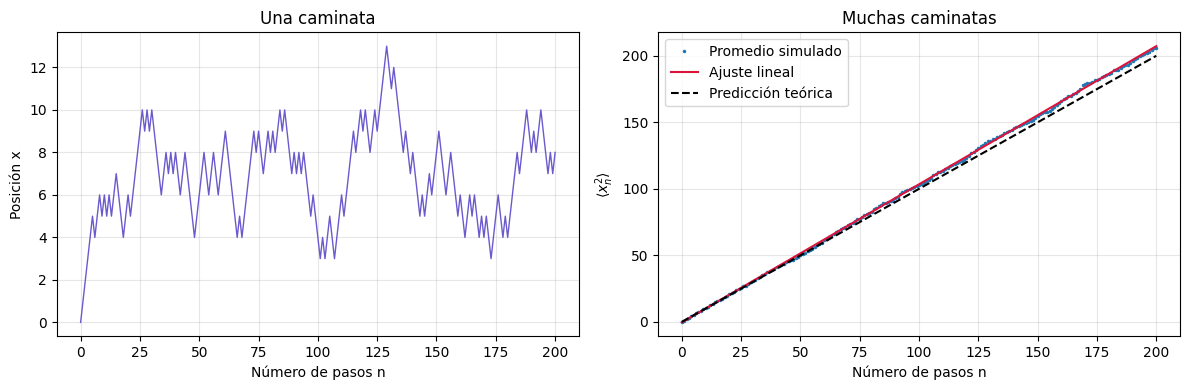

Pendiente=1.03839; intercepto=-0.40870
D estimado=0.51919; D teórico=0.50000 (longitud²/tiempo)


In [4]:
import random
import matplotlib.pyplot as plt

# ==============================================================================
#  C: Experimento completo, exportación y figura
# ==============================================================================
#  Parámetros del experimento
K, N = 2000, 200            # caminantes y pasos por caminante
a, delta_t = 1.0, 1.0       # longitud de paso e intervalo de tiempo
semilla = 2026              # semilla del resultado entregado

#  Simulación y ajuste lineal de <x_n^2> frente a n
media_x, media_x2 = simular_caminatas(K, N, a, semilla)
pasos = list(range(N + 1))
pendiente, intercepto = ajuste_lineal(pasos, media_x2)

#  Coeficiente de difusión: estimado (del ajuste) y teórico
D_estimado = pendiente / (2 * delta_t)
D_teorico = (a * a) / (2 * delta_t)
ajuste = [pendiente * n + intercepto for n in pasos]   # recta ajustada, para graficar

#  Una trayectoria individual, para comparar con el promedio ---
trayectoria = caminar(N, a, random.Random(2027))

#  Guardar los resultados en un archivo CSV ---
with open("caminata_difusion.csv", "w", encoding="utf-8") as archivo:
    archivo.write("n,media_x,media_x2,ajuste\n")
    for n in pasos:
        archivo.write(f"{n},{media_x[n]},{media_x2[n]},{ajuste[n]}\n")

# Figura: trayectoria individual (izquierda) y promedios (derecha)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(pasos, trayectoria, color="slateblue", linewidth=1)
ax1.set(xlabel="Número de pasos n", ylabel="Posición x", title="Una caminata")
ax2.plot(pasos, media_x2, ".", markersize=3, label="Promedio simulado")
ax2.plot(pasos, ajuste, color="crimson", label="Ajuste lineal")
ax2.plot(pasos, [n * a * a for n in pasos], "--", color="black", label="Predicción teórica")
ax2.set(xlabel="Número de pasos n", ylabel=r"$\langle x_n^2\rangle$", title="Muchas caminatas")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.savefig("caminata_difusion.png", dpi=180, bbox_inches="tight")
plt.show()

#  Resumen numérico
print(f"Pendiente={pendiente:.5f}; intercepto={intercepto:.5f}")
print(f"D estimado={D_estimado:.5f}; D teórico={D_teorico:.5f} (longitud²/tiempo)")

##Parte D

In [6]:
class GeneradorLCG:
    """Generador lineal congruente r_{i+1} = (a r_i + c) mod M.

    El método random() devuelve r/M en [0, 1), con la misma interfaz que
    random.Random, de modo que puede reemplazarlo en simular_caminatas.
    """

    # --- Constructor: guarda los parámetros y el estado inicial (la semilla) ---
    def __init__(self, a, c, M, semilla):
        self.a, self.c, self.M = a, c, M
        self.r = semilla % M          # el estado siempre está en 0, ..., M-1

    # --- Un número nuevo: actualiza el estado y lo escala a [0, 1) ---
    def random(self):
        self.r = (self.a * self.r + self.c) % self.M   # recurrencia congruencial
        return self.r / self.M                       # división real


D con random.Random : 0.5192
D con LCG deficiente: 0.0862
D con LCG drand48   : 0.4855   (teórico 0.5)


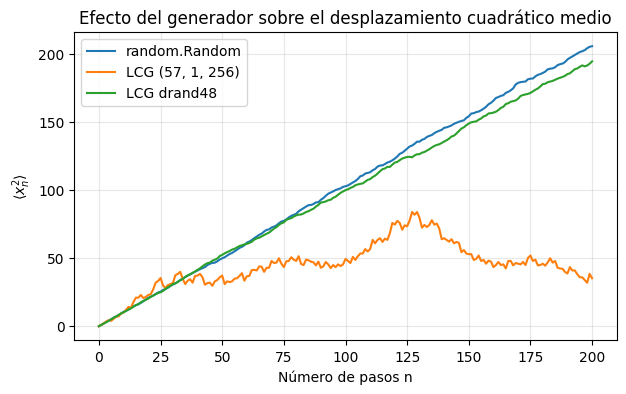


Posiciones en n = 0, 256, 512, 768, 1024:
[0.0, 0.0, 0.0, 0.0, 0.0]


In [7]:

# --- Parámetros comunes a los tres experimentos ---
K_gen, N_gen = 2000, 200
pasos_gen = list(range(N_gen + 1))

# --- ACTIVIDADES D1 Y D2: Simulación y cálculo de D con tres generadores ---
_, x2_bueno = simular_caminatas(K_gen, N_gen, 1.0, 2026)
_, x2_malo = simular_caminatas(K_gen, N_gen, 1.0, None, generador=GeneradorLCG(57, 1, 256, 10))
_, x2_drand48 = simular_caminatas(K_gen, N_gen, 1.0, None, generador=GeneradorLCG(0x5DEECE66D, 11, 2**48, 10))

# Pendiente de <x_n^2> para cada generador
m_bueno, _ = ajuste_lineal(pasos_gen, x2_bueno)
m_malo, _ = ajuste_lineal(pasos_gen, x2_malo)
m_drand48, _ = ajuste_lineal(pasos_gen, x2_drand48)

# Coeficiente de difusión D = pendiente / (2 dt), con dt = 1
D_bueno = m_bueno / 2
D_lcg_malo = m_malo / 2
D_drand48 = m_drand48 / 2

print(f"D con random.Random : {D_bueno:.4f}")
print(f"D con LCG deficiente: {D_lcg_malo:.4f}")
print(f"D con LCG drand48   : {D_drand48:.4f}   (teórico 0.5)")


# --- ACTIVIDAD D3: Gráfica comparativa de <x_n^2> frente a n ---
plt.figure(figsize=(7, 4))
plt.plot(pasos_gen, x2_bueno, label="random.Random")
plt.plot(pasos_gen, x2_malo, label="LCG (57, 1, 256)")
plt.plot(pasos_gen, x2_drand48, label="LCG drand48")
plt.xlabel("Número de pasos n")
plt.ylabel(r"$\langle x_n^2\rangle$")
plt.title("Efecto del generador sobre el desplazamiento cuadrático medio")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# --- ACTIVIDAD D4: Caminata larga de 1024 pasos con LCG deficiente ---
trayectoria_lcg_larga = caminar(1024, 1.0, GeneradorLCG(57, 1, 256, 10))
print("\nPosiciones en n = 0, 256, 512, 768, 1024:")
print([trayectoria_lcg_larga[n] for n in (0, 256, 512, 768, 1024)])


## Parte E — Difusión en unidades reales

In [8]:
import math

# --- Datos físicos ---
D_O2 = 2e-9          # m^2/s, coeficiente de difusión del oxígeno en agua
dt_fisico = 1e-6     # s, intervalo de tiempo entre pasos

# --- ACTIVIDAD E1: Longitud de paso física ---
a_fisico = math.sqrt(2 * D_O2 * dt_fisico)


# --- ACTIVIDAD E2: Coeficiente de difusión simulado en m^2/s ---
D_sim = pendiente * (a_fisico**2) / (2 * dt_fisico)


# --- ACTIVIDADES E3 Y E4: Tiempos característicos de difusión t = L^2 / (2D) ---
def tiempo_difusion(L, D):
    """Tiempo t = L^2/(2D) para alcanzar una distancia RMS L en una dimensión."""
    return (L**2) / (2 * D)

t_celula = tiempo_difusion(10e-6, D_O2)   # 10 µm (célula)
t_mm = tiempo_difusion(1e-3, D_O2)        # 1 mm
t_cm = tiempo_difusion(1e-2, D_O2)        # 1 cm
t_m = tiempo_difusion(1.0, D_O2)          # 1 m


# --- ACTIVIDAD E5: Número de pasos N para difundir 1 cm ---
N_cm = (1e-2 / a_fisico)**2


# --- Impresión de resultados en unidades legibles ---
print(f"a_fisico = {a_fisico*1e9:.1f} nm;  D_sim = {D_sim:.3e} m^2/s")
print(f"Tiempo 10 µm (célula): {t_celula:.3g} s")
print(f"Tiempo 1 mm : {t_mm:.3g} s = {t_mm/60:.3g} min")
print(f"Tiempo 1 cm : {t_cm:.3g} s = {t_cm/3600:.3g} h")
print(f"Tiempo 1 m  : {t_m/(3600*24*365.25):.3g} años")
print(f"Pasos necesarios para 1 cm: {N_cm:.2e}")


a_fisico = 63.2 nm;  D_sim = 2.077e-09 m^2/s
Tiempo 10 µm (célula): 0.025 s
Tiempo 1 mm : 250 s = 4.17 min
Tiempo 1 cm : 2.5e+04 s = 6.94 h
Tiempo 1 m  : 7.92 años
Pasos necesarios para 1 cm: 2.50e+10


## Verificación final PASS/FAIL

In [9]:

import csv
import math
from pathlib import Path

# --- Registro de resultados: imprime PASS/FAIL y guarda cada veredicto ---
veredictos = []
def informar(nombre, condicion, detalle=""):
    estado = "PASS" if condicion else "FAIL"
    veredictos.append(condicion)
    print(f"{estado} | {nombre}" + (f" — {detalle}" if detalle else ""))

# --- Generador de prueba: devuelve valores fijados de antemano ---
class RngControlado:
    def __init__(self, valores):
        self.valores = iter(valores)
    def random(self):
        return next(self.valores)

# --- Prueba 1: regla del paso (umbral en 0.5) ---
try:
    pasos_prueba = [generar_paso(RngControlado([u]), 2.0) for u in (0.0, 0.49, 0.5, 0.99)]
    informar("Regla del paso y umbral 0.5", pasos_prueba == [2.0, 2.0, -2.0, -2.0])
except Exception as exc:
    informar("Regla del paso y umbral 0.5", False, str(exc))

# --- Prueba 2: trayectoria con números controlados ---
try:
    posiciones_prueba = list(caminar(4, 2.0, RngControlado([0.1, 0.7, 0.2, 0.8])))
    informar("Trayectoria y posición inicial", posiciones_prueba == [0.0, 2.0, 0.0, 2.0, 0.0])
except Exception as exc:
    informar("Trayectoria y posición inicial", False, str(exc))

# --- Prueba 3: ajuste lineal con datos exactos ---
try:
    m_prueba, b_prueba = ajuste_lineal([0, 1, 2, 3], [2, 5, 8, 11])
    informar("Ajuste lineal con datos conocidos", math.isclose(m_prueba, 3.0, abs_tol=1e-10) and math.isclose(b_prueba, 2.0, abs_tol=1e-10))
except Exception as exc:
    informar("Ajuste lineal con datos conocidos", False, str(exc))

# --- Pruebas 4-7: estructura, reproducibilidad, simetría y crecimiento difusivo ---
try:
    mx1, mx21 = simular_caminatas(2000, 100, 1.0, 12345)
    mx2, mx22 = simular_caminatas(2000, 100, 1.0, 12345)
    estructura = (len(mx1) == len(mx21) == 101 and
                  math.isclose(mx1[0], 0.0) and math.isclose(mx21[0], 0.0) and
                  all(math.isfinite(float(v)) for v in list(mx1) + list(mx21)))
    informar("Longitud, origen y valores finitos", estructura)
    informar("Reproducibilidad con la misma semilla", list(mx1) == list(mx2) and list(mx21) == list(mx22))
    if estructura:
        exactitud_media = all(abs(mx1[n]) <= 0.20*math.sqrt(n) + 0.1 for n in (25, 50, 100))
        informar("Media de posición compatible con simetría", exactitud_media)
        m_test, _ = ajuste_lineal(list(range(101)), mx21)
        informar("Crecimiento difusivo promedio", math.isfinite(m_test) and abs(m_test - 1.0) < 0.15, f"pendiente={m_test:.4f}")
    else:
        informar("Media de posición compatible con simetría", False)
        informar("Crecimiento difusivo promedio", False)
except Exception as exc:
    for nombre in ("Longitud, origen y valores finitos", "Reproducibilidad con la misma semilla", "Media de posición compatible con simetría", "Crecimiento difusivo promedio"):
        informar(nombre, False, str(exc))

# --- Prueba 8: parámetros inválidos deben producir ValueError ---
try:
    rechazos = []
    for llamada in (lambda: caminar(-1, 1.0, random.Random(1)),
                    lambda: simular_caminatas(0, 10, 1.0, 1),
                    lambda: ajuste_lineal([1, 1], [2, 3])):
        try:
            llamada()
            rechazos.append(False)
        except ValueError:
            rechazos.append(True)
    informar("Parámetros y ajuste degenerado rechazados", all(rechazos))
except Exception as exc:
    informar("Parámetros y ajuste degenerado rechazados", False, str(exc))

# --- Prueba 9: archivo CSV completo y consistente ---
try:
    datos = list(csv.DictReader(open("caminata_difusion.csv", encoding="utf-8")))
    columnas = set(datos[0]) if datos else set()
    valido = (len(datos) == N + 1 and columnas == {"n", "media_x", "media_x2", "ajuste"}
              and [int(fila["n"]) for fila in datos] == list(range(N+1)))
    if valido:
        valido = all(math.isclose(float(fila["media_x2"]), float(media_x2[i]), abs_tol=1e-10)
                     and math.isclose(float(fila["ajuste"]), pendiente*i + intercepto, abs_tol=1e-9)
                     for i, fila in enumerate(datos))
    informar("CSV completo y consistente con el ajuste", valido)
except Exception as exc:
    informar("CSV completo y consistente con el ajuste", False, str(exc))

# --- Prueba 10: conversión de la pendiente al coeficiente de difusión ---
try:
    correcto_D = (math.isclose(D_estimado, pendiente/(2*delta_t), rel_tol=1e-10, abs_tol=1e-10)
                   and math.isclose(D_teorico, a*a/(2*delta_t), rel_tol=1e-10, abs_tol=1e-10))
    informar("Conversión de la pendiente al coeficiente de difusión", correcto_D)
except Exception as exc:
    informar("Conversión de la pendiente al coeficiente de difusión", False, str(exc))

# --- Prueba 11: simular_caminatas acepta un generador externo (Parte D) ---
try:
    _, x2_ctrl = simular_caminatas(1, 2, 1.0, None, generador=RngControlado([0.1, 0.7]))
    informar("simular_caminatas acepta un generador externo", [float(t) for t in x2_ctrl] == [0.0, 1.0, 0.0])
except Exception as exc:
    informar("simular_caminatas acepta un generador externo", False, str(exc))

# --- Pruebas 12-13: coeficiente de difusión con el LCG deficiente y con drand48 ---
try:
    informar("LCG deficiente: resultado del experimento especificado", math.isfinite(D_lcg_malo) and math.isclose(D_lcg_malo, 0.08623725432244717, rel_tol=1e-6, abs_tol=1e-8), f"D_lcg_malo={D_lcg_malo:.4f}")
    informar("LCG drand48: coeficiente de difusión compatible con 0.5", abs(D_drand48 - 0.5) < 0.075, f"D_drand48={D_drand48:.4f}")
except Exception as exc:
    informar("LCG deficiente: resultado del experimento especificado", False, str(exc))
    informar("LCG drand48: coeficiente de difusión compatible con 0.5", False, str(exc))

# --- Pruebas 14-15: unidades reales (Parte E) ---
try:
    ok_a = math.isclose(a_fisico, math.sqrt(2*D_O2*dt_fisico), rel_tol=1e-9)
    ok_Dsim = math.isclose(D_sim, pendiente*a_fisico**2/(2*dt_fisico), rel_tol=1e-9)
    informar("Paso físico y coeficiente de difusión en m²/s", ok_a and ok_Dsim, f"a={a_fisico*1e9:.1f} nm, D_sim={D_sim:.2e} m²/s")
    ok_t = (math.isclose(t_celula, 0.025, rel_tol=1e-9) and math.isclose(t_cm, 2.5e4, rel_tol=1e-9)
            and math.isclose(t_mm, 250.0, rel_tol=1e-9) and math.isclose(t_m, 2.5e8, rel_tol=1e-9)
            and math.isclose(N_cm, (1e-2/a_fisico)**2, rel_tol=1e-6))
    informar("Tiempos de difusión y número de pasos", ok_t, f"t(10 µm)={t_celula:.3g} s, t(1 cm)={t_cm/3600:.2f} h")
except Exception as exc:
    informar("Paso físico y coeficiente de difusión en m²/s", False, str(exc))
    informar("Tiempos de difusión y número de pasos", False, str(exc))

# --- Prueba determinista de la caminata larga ---
try:
    estado_ref = 10
    x_ref = 0.0
    recorrido_ref = [x_ref]
    for _ in range(1024):
        estado_ref = (57*estado_ref + 1) % 256
        x_ref += 1.0 if estado_ref/256 < 0.5 else -1.0
        recorrido_ref.append(x_ref)
    informar("Caminata larga con LCG: trayectoria y retornos periódicos",
             list(trayectoria_lcg_larga) == recorrido_ref)
except Exception as exc:
    informar("Caminata larga con LCG: trayectoria y retornos periódicos", False, str(exc))

# --- Prueba 16: la figura fue guardada ---
figura = Path("caminata_difusion.png")
informar("Figura generada", figura.is_file() and figura.stat().st_size > 1000)

# --- Resumen final ---
print(f"\nResumen: {sum(veredictos)}/{len(veredictos)} PASS")


PASS | Regla del paso y umbral 0.5
PASS | Trayectoria y posición inicial
PASS | Ajuste lineal con datos conocidos
PASS | Longitud, origen y valores finitos
PASS | Reproducibilidad con la misma semilla
PASS | Media de posición compatible con simetría
PASS | Crecimiento difusivo promedio — pendiente=1.0147
PASS | Parámetros y ajuste degenerado rechazados
PASS | CSV completo y consistente con el ajuste
PASS | Conversión de la pendiente al coeficiente de difusión
PASS | simular_caminatas acepta un generador externo
PASS | LCG deficiente: resultado del experimento especificado — D_lcg_malo=0.0862
PASS | LCG drand48: coeficiente de difusión compatible con 0.5 — D_drand48=0.4855
PASS | Paso físico y coeficiente de difusión en m²/s — a=63.2 nm, D_sim=2.08e-09 m²/s
PASS | Tiempos de difusión y número de pasos — t(10 µm)=0.025 s, t(1 cm)=6.94 h
PASS | Caminata larga con LCG: trayectoria y retornos periódicos
PASS | Figura generada

Resumen: 17/17 PASS
